# LOB 101 — Analyse du Limit Order Book
**Données** : TOTF (Total SA) — Euronext Paris, 2014

Objectifs (dernière slide) :
1. Comprendre les données
2. Reproduire les *stylised facts*
3. Créer une visualisation du Limit Order Book

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11

DATA_PATH  = '../Data MDS/'
TRADE_FILE = DATA_PATH + 'TOTF_trade_2014_2017.csv.gz'
BOOK_FILE  = DATA_PATH + 'TOTF_book_2014-04-13_to_2014-10-12.csv.gz'

---
## Partie 1 — Comprendre les données

In [2]:
# --- Chargement d'un échantillon représentatif (5 jours) ---
DAYS = ['2014-04-14', '2014-04-15', '2014-04-16', '2014-04-22', '2014-04-23']

# Trade : lecture par chunks + filtre sur les 5 jours
trade_chunks = []
for chunk in pd.read_csv(TRADE_FILE, chunksize=200_000):
    sub = chunk[chunk['date'].isin(DAYS)]
    if len(sub):
        trade_chunks.append(sub)
df_trade = pd.concat(trade_chunks, ignore_index=True)
df_trade['datetime'] = pd.to_datetime(df_trade['date'] + ' ' + df_trade['time'])

# Book : lecture par chunks + filtre sur les 5 jours
book_chunks = []
for chunk in pd.read_csv(BOOK_FILE, chunksize=200_000):
    sub = chunk[chunk['date'].isin(DAYS)]
    if len(sub):
        book_chunks.append(sub)
    if chunk['date'].max() > DAYS[-1]:
        break
df_book = pd.concat(book_chunks, ignore_index=True)
df_book['datetime'] = pd.to_datetime(df_book['date'] + ' ' + df_book['time'])

print(f'Trades  : {len(df_trade):,} lignes | Jours : {df_trade["date"].nunique()}')
print(f'Book    : {len(df_book):,} lignes  | Jours : {df_book["date"].nunique()}')

Trades  : 29,096 lignes | Jours : 5
Book    : 2,521,765 lignes  | Jours : 5


In [3]:
print('=== TRADE (5 premières lignes) ===')
display(df_trade[['date','time','trade.price','trade.volume']].head())

print('\n=== BOOK (5 premières lignes) ===')
display(df_book[['date','time','bid_1','bidQ_1','ask_1','askQ_1','bid_2','ask_2']].head())

print('\n=== STATISTIQUES DESCRIPTIVES TRADE ===')
display(df_trade[['trade.price','trade.volume']].describe())

print('\n=== STATISTIQUES DESCRIPTIVES BOOK (niveau 1) ===')
display(df_book[['bid_1','bidQ_1','ask_1','askQ_1']].describe())

=== TRADE (5 premières lignes) ===


,date,time,trade.price,trade.volume
0,2014-04-14,09:30:03,47.670000,245.0
1,2014-04-14,09:30:04,47.665000,159.0
2,2014-04-14,09:30:04,47.657878,662.0
3,2014-04-14,09:30:04,47.655000,200.0
4,2014-04-14,09:30:04,47.660000,364.0



=== BOOK (5 premières lignes) ===


,date,time,bid_1,bidQ_1,ask_1,askQ_1,bid_2,ask_2
0,2014-04-14,09:30:01,47.67,245.0,47.68,3176.0,47.665,47.685
1,2014-04-14,09:30:01,47.67,245.0,47.68,3176.0,47.665,47.685
2,2014-04-14,09:30:01,47.67,245.0,47.68,3176.0,47.665,47.685
3,2014-04-14,09:30:01,47.67,245.0,47.68,4052.0,47.665,47.685
4,2014-04-14,09:30:01,47.67,245.0,47.68,4052.0,47.665,47.685



=== STATISTIQUES DESCRIPTIVES TRADE ===


,trade.price,trade.volume
count,29096.000000,2.909600e+04
mean,49.162851,7.276875e+04
std,0.495555,3.019020e+05
min,46.345000,1.000000e+00
25%,48.985000,1.600000e+02
50%,49.200000,3.690000e+02
75%,49.559560,8.090000e+02
max,50.000000,3.525725e+06



=== STATISTIQUES DESCRIPTIVES BOOK (niveau 1) ===


,bid_1,bidQ_1,ask_1,askQ_1
count,2.521765e+06,2.521765e+06,2.521765e+06,2.521765e+06
mean,4.906874e+01,2.332310e+03,4.907979e+01,2.534568e+03
std,2.307420e+00,2.324924e+04,2.292047e+00,2.444546e+04
min,0.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00
25%,4.898000e+01,5.950000e+02,4.899000e+01,5.910000e+02
50%,4.918500e+01,1.203000e+03,4.920000e+01,1.223000e+03
75%,4.953000e+01,2.078000e+03,4.954000e+01,2.117000e+03
max,5.231000e+01,1.006954e+06,4.978000e+01,9.814690e+05


In [4]:
# Spread et mid-price
df_book['spread'] = (df_book['ask_1'] - df_book['bid_1']).round(4)
df_book['mid']    = (df_book['bid_1'] + df_book['ask_1']) / 2

print('Spread moyen  :', round(df_book['spread'].mean(), 4), 'EUR')
print('Spread median :', round(df_book['spread'].median(), 4), 'EUR')
print('Mid-price moyen:', round(df_book['mid'].mean(), 4), 'EUR')

Spread moyen  : 0.011 EUR
Spread median : 0.01 EUR
Mid-price moyen: 49.0743 EUR


---
## Partie 2 — Stylised Facts

Les 6 faits stylisés du LOB (slide 4) :
1. **Long memory** in order flow
2. **Bid-ask bounce** (mean reversion a haute frequence)
3. **Impact de marche concave** (square-root law)
4. **Profil intraday en U** des volumes
5. **Queues epaisses** (heavy tails) des rendements et volumes
6. **Volatility clustering**

In [5]:
# ============================================================
# Preparation : Significant Price Changes + Coarse-Graining
# (methodologie de la slide 7)
# ============================================================

# Filtrer les prix invalides (mid = 0 = donnees corrompues)
df_book_clean = df_book[df_book['mid'] > 0].copy()

TICK  = 0.005   # tolerance = demi tick (tick = 0.01 EUR)
GRAIN = 20      # coarse-graining : blocs de 20 ticks significatifs (~3 min)

all_sig = []

for day, grp in df_book_clean.groupby('date'):
    grp = grp.sort_values('datetime').copy().reset_index(drop=True)
    hour = grp['datetime'].dt.hour + grp['datetime'].dt.minute / 60
    grp = grp[(hour >= 9.5) & (hour < 17.5)].copy().reset_index(drop=True)

    grp['prev_bid'] = grp['bid_1'].shift(1)
    grp['prev_ask'] = grp['ask_1'].shift(1)

    # Significant price change : nouveau bid == ancien ask  OU  nouveau ask == ancien bid
    # (le prix a traverse le spread : vrai signal de marche)
    sig_mask = (
        (np.abs(grp['bid_1'] - grp['prev_ask']) < TICK) |
        (np.abs(grp['ask_1'] - grp['prev_bid']) < TICK)
    )
    sig = grp[sig_mask].copy()
    sig['mid_sig'] = (sig['bid_1'] + sig['ask_1']) / 2

    # Log-return entre deux changements significatifs consecutifs (dans la meme journee)
    sig['r'] = np.log(sig['mid_sig'] / sig['mid_sig'].shift(1))

    # Garder uniquement les vrais mouvements de prix (finis, non nuls)
    sig = sig[np.isfinite(sig['r']) & (sig['r'] != 0)]
    all_sig.append(sig)

sig_all = pd.concat(all_sig, ignore_index=True)

# Coarse-graining : sommer les rendements par blocs de 20 ticks significatifs
n = (len(sig_all) // GRAIN) * GRAIN
returns = pd.Series(
    sig_all['r'].iloc[:n].values.reshape(-1, GRAIN).sum(axis=1)
)

print(f'Mises a jour book (marche)         : {len(df_book_clean):,}')
print(f'Significant price changes           : {len(sig_all):,}')
print(f'Blocs coarse-grained (n={GRAIN})    : {len(returns):,}')
print(f'Kurtosis (ticks sig.)               : {sig_all["r"].kurtosis():.1f}')
print(f'ACF lag-1 signe (long memory)       : {pd.Series(np.sign(returns)).autocorr(1):.4f}')
print(f'ACF lag-1 rendement (bid-ask bounce): {returns.autocorr(1):.4f}')

Mises a jour book (marche)         : 2,516,568
Significant price changes           : 53,505
Blocs coarse-grained (n=20)    : 2,675
Kurtosis (ticks sig.)               : 26709.0
ACF lag-1 signe (long memory)       : 0.0187
ACF lag-1 rendement (bid-ask bounce): -0.0741


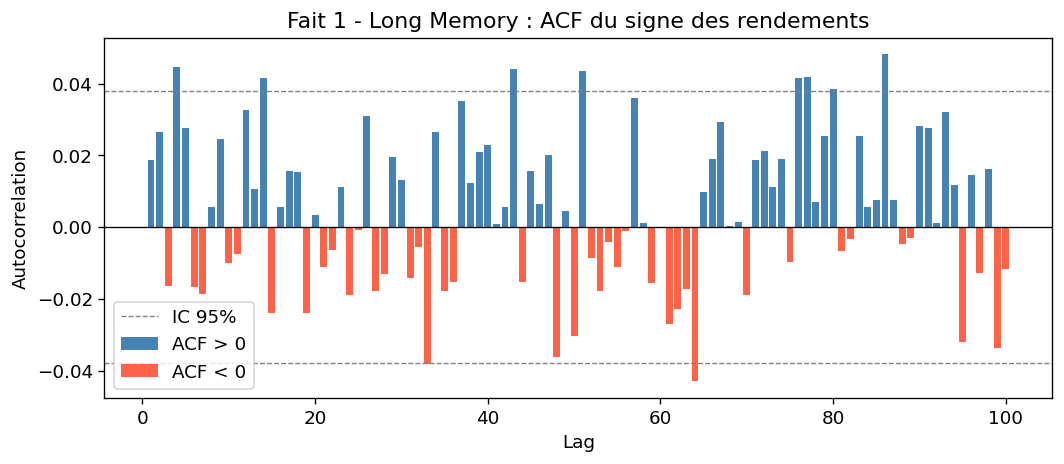

In [6]:
# ============================================================
# Fait 1 : Long Memory dans le flux d'ordres
# ACF du signe des rendements : persistance positive sur de nombreux lags
# ============================================================
from statsmodels.tsa.stattools import acf

sign_series = np.sign(returns).replace(0, np.nan).dropna()
max_lag = 100
acf_vals = acf(sign_series, nlags=max_lag, fft=True)

fig, ax = plt.subplots(figsize=(9, 4))
lags = np.arange(1, max_lag + 1)
pos_mask = acf_vals[1:] > 0
ax.bar(lags[pos_mask],  acf_vals[1:][pos_mask],  color='steelblue', label='ACF > 0')
ax.bar(lags[~pos_mask], acf_vals[1:][~pos_mask], color='tomato',    label='ACF < 0')
ax.axhline(0, color='black', linewidth=0.8)
ax.axhline( 1.96/np.sqrt(len(sign_series)), color='gray', linestyle='--', linewidth=0.8, label='IC 95%')
ax.axhline(-1.96/np.sqrt(len(sign_series)), color='gray', linestyle='--', linewidth=0.8)
ax.set_xlabel('Lag')
ax.set_ylabel('Autocorrelation')
ax.set_title('Fait 1 - Long Memory : ACF du signe des rendements')
ax.legend()
plt.tight_layout()
plt.savefig('fact1_long_memory.png')
plt.show()

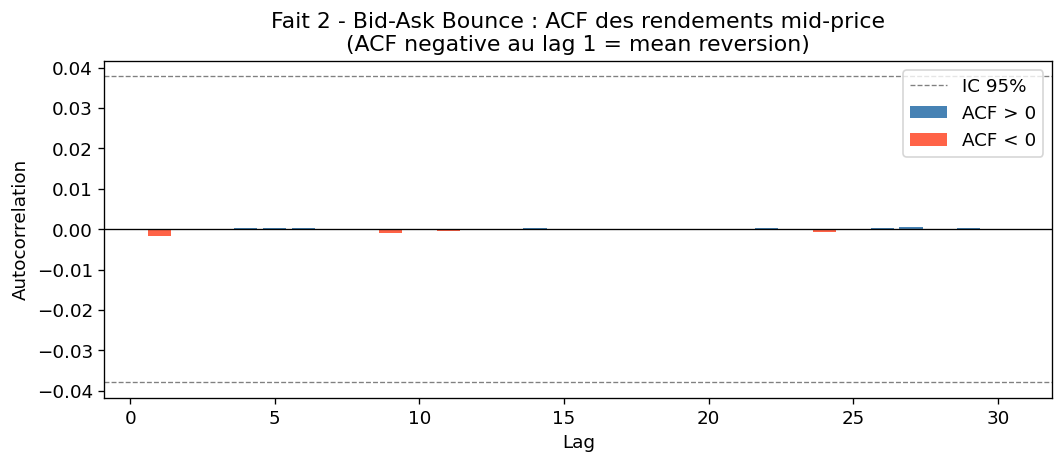

In [7]:
# ============================================================
# Fait 2 : Bid-Ask Bounce (mean reversion a haute frequence)
# ACF des rendements : autocorrelation negative au lag 1
# ============================================================
acf_ret = acf(returns, nlags=30, fft=True)

fig, ax = plt.subplots(figsize=(9, 4))
lags_r = np.arange(1, 31)
pos_r = acf_ret[1:] > 0
ax.bar(lags_r[pos_r],  acf_ret[1:][pos_r],  color='steelblue', label='ACF > 0')
ax.bar(lags_r[~pos_r], acf_ret[1:][~pos_r], color='tomato',    label='ACF < 0')
ax.axhline(0, color='black', linewidth=0.8)
ax.axhline( 1.96/np.sqrt(len(returns)), color='gray', linestyle='--', linewidth=0.8, label='IC 95%')
ax.axhline(-1.96/np.sqrt(len(returns)), color='gray', linestyle='--', linewidth=0.8)
ax.set_xlabel('Lag')
ax.set_ylabel('Autocorrelation')
ax.set_title('Fait 2 - Bid-Ask Bounce : ACF des rendements mid-price\n(ACF negative au lag 1 = mean reversion)')
ax.legend()
plt.tight_layout()
plt.savefig('fact2_bidask_bounce.png')
plt.show()

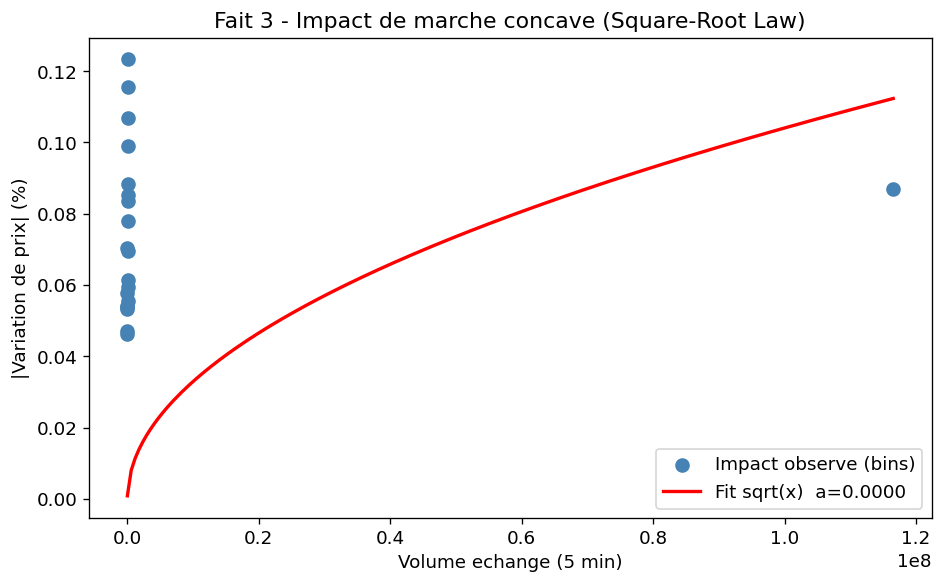

In [8]:
# ============================================================
# Fait 3 : Impact de marche concave (Square-Root Law)
# ============================================================
from scipy.optimize import curve_fit

df_trade_mkt = df_trade.copy()
df_trade_mkt['hour'] = df_trade_mkt['datetime'].dt.hour + df_trade_mkt['datetime'].dt.minute / 60
df_trade_mkt = df_trade_mkt[(df_trade_mkt['hour'] >= 9.5) & (df_trade_mkt['hour'] < 17.5)]
df_trade_mkt = df_trade_mkt.set_index('datetime').sort_index()

vol_5min    = df_trade_mkt['trade.volume'].resample('5min').sum()
price_5min  = df_trade_mkt['trade.price'].resample('5min').last()
impact_5min = price_5min.pct_change().abs() * 100

df_impact = pd.DataFrame({'volume': vol_5min, 'impact': impact_5min}).dropna()
df_impact = df_impact[(df_impact['volume'] > 0) & (df_impact['impact'] > 0)]

df_impact['vol_bin'] = pd.qcut(df_impact['volume'], q=20, duplicates='drop')
impact_by_vol = df_impact.groupby('vol_bin', observed=True)['impact'].mean()
vol_centers   = df_impact.groupby('vol_bin', observed=True)['volume'].mean()

def sqrt_law(x, a):
    return a * np.sqrt(x)

x_data = vol_centers.values
y_data = impact_by_vol.values
popt, _ = curve_fit(sqrt_law, x_data, y_data)
x_fit = np.linspace(x_data.min(), x_data.max(), 200)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x_data, y_data, color='steelblue', s=60, zorder=3, label='Impact observe (bins)')
ax.plot(x_fit, sqrt_law(x_fit, *popt), 'r-', linewidth=2, label=f'Fit sqrt(x)  a={popt[0]:.4f}')
ax.set_xlabel('Volume echange (5 min)')
ax.set_ylabel('|Variation de prix| (%)')
ax.set_title('Fait 3 - Impact de marche concave (Square-Root Law)')
ax.legend()
plt.tight_layout()
plt.savefig('fact3_market_impact.png')
plt.show()

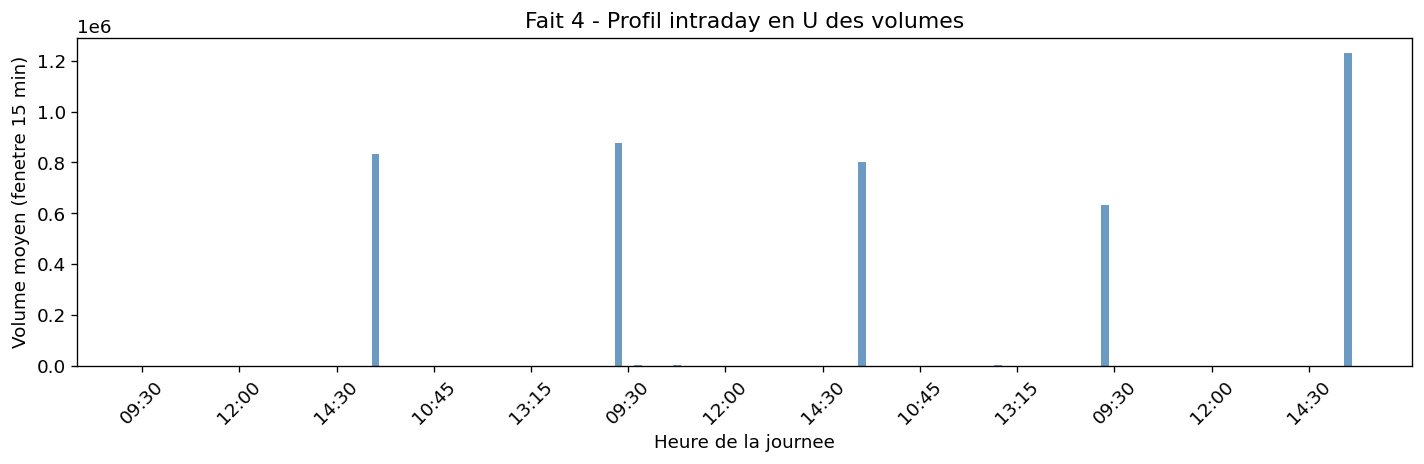

In [9]:
# ============================================================
# Fait 4 : Profil intraday en U des volumes
# ============================================================
df_trade_mkt2 = df_trade.copy()
df_trade_mkt2['hour_min'] = df_trade_mkt2['datetime'].dt.hour + df_trade_mkt2['datetime'].dt.minute / 60
df_trade_mkt2 = df_trade_mkt2[(df_trade_mkt2['hour_min'] >= 9.5) & (df_trade_mkt2['hour_min'] < 17.5)]
df_trade_mkt2['time_bin'] = df_trade_mkt2['datetime'].dt.floor('15min')

intraday = df_trade_mkt2.groupby('time_bin')['trade.volume'].mean().reset_index()
intraday['time_label'] = intraday['time_bin'].dt.strftime('%H:%M')

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(intraday)), intraday['trade.volume'], color='steelblue', alpha=0.8)
step = max(1, len(intraday) // 12)
ax.set_xticks(range(0, len(intraday), step))
ax.set_xticklabels(intraday['time_label'].iloc[::step], rotation=45)
ax.set_xlabel('Heure de la journee')
ax.set_ylabel('Volume moyen (fenetre 15 min)')
ax.set_title('Fait 4 - Profil intraday en U des volumes')
plt.tight_layout()
plt.savefig('fact4_intraday_u_shape.png')
plt.show()

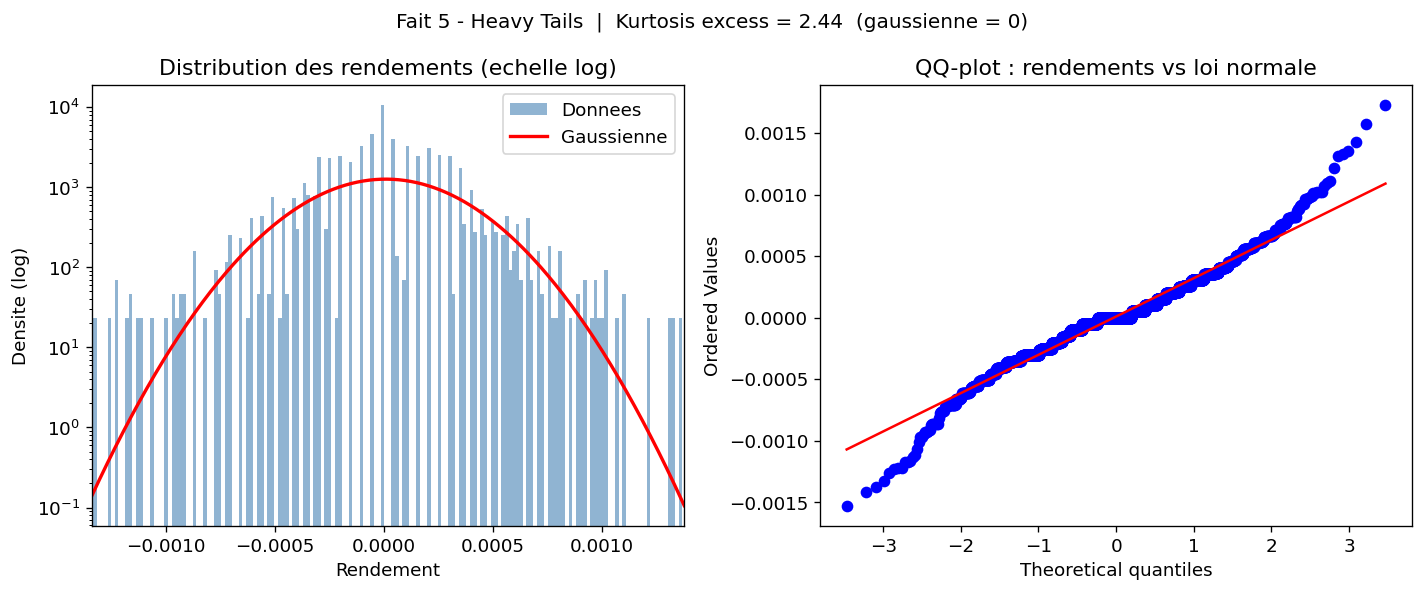

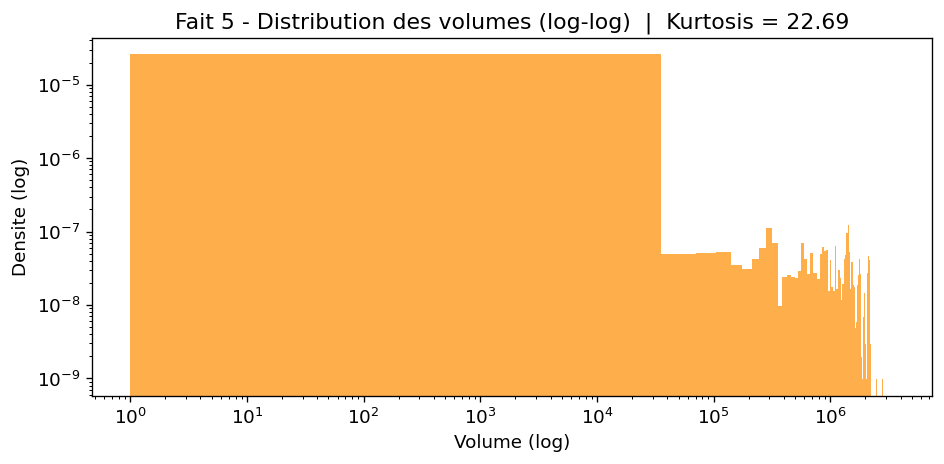

In [10]:
# ============================================================
# Fait 5 : Queues epaisses (Heavy Tails)
# ============================================================
from scipy import stats

ret_clean = returns.replace([np.inf, -np.inf], np.nan).dropna()
z = (ret_clean - ret_clean.mean()) / ret_clean.std()
ret_clean = ret_clean[z.abs() < 10]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
x_range = np.linspace(ret_clean.quantile(0.001), ret_clean.quantile(0.999), 300)
mu, sigma = ret_clean.mean(), ret_clean.std()
ax.hist(ret_clean, bins=200, density=True, color='steelblue', alpha=0.6, label='Donnees')
ax.plot(x_range, stats.norm.pdf(x_range, mu, sigma), 'r-', linewidth=2, label='Gaussienne')
ax.set_yscale('log')
ax.set_xlim(ret_clean.quantile(0.001), ret_clean.quantile(0.999))
ax.set_xlabel('Rendement')
ax.set_ylabel('Densite (log)')
ax.set_title('Distribution des rendements (echelle log)')
ax.legend()

ax2 = axes[1]
stats.probplot(ret_clean, dist='norm', plot=ax2)
ax2.set_title('QQ-plot : rendements vs loi normale')
ax2.get_lines()[1].set_color('red')

kurt = stats.kurtosis(ret_clean)
fig.suptitle(f'Fait 5 - Heavy Tails  |  Kurtosis excess = {kurt:.2f}  (gaussienne = 0)', fontsize=12)
plt.tight_layout()
plt.savefig('fact5_heavy_tails.png')
plt.show()

# Distribution des volumes (log-log)
vol_clean = df_trade['trade.volume'].dropna()
fig2, ax3 = plt.subplots(figsize=(8, 4))
ax3.hist(vol_clean, bins=100, density=True, color='darkorange', alpha=0.7)
ax3.set_yscale('log')
ax3.set_xscale('log')
ax3.set_xlabel('Volume (log)')
ax3.set_ylabel('Densite (log)')
ax3.set_title(f'Fait 5 - Distribution des volumes (log-log)  |  Kurtosis = {stats.kurtosis(vol_clean):.2f}')
plt.tight_layout()
plt.savefig('fact5_heavy_tails_volume.png')
plt.show()

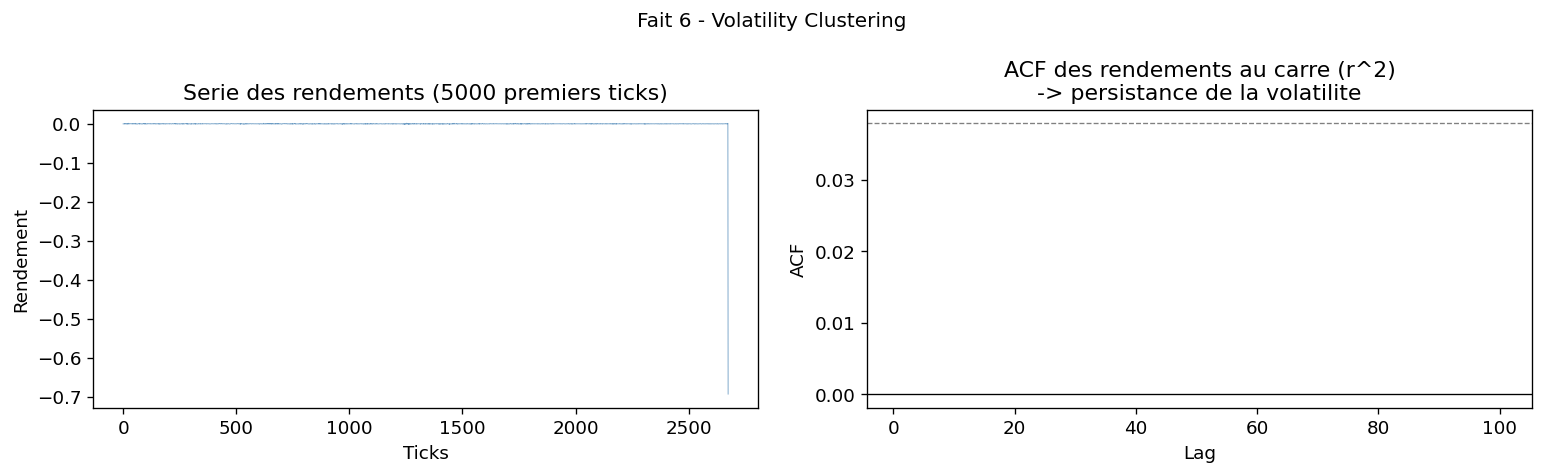

In [11]:
# ============================================================
# Fait 6 : Volatility Clustering
# ACF des rendements au carre
# ============================================================
ret_sq = returns ** 2
acf_sq = acf(ret_sq, nlags=100, fft=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.plot(returns.values[:5000], color='steelblue', linewidth=0.5, alpha=0.8)
ax.set_xlabel('Ticks')
ax.set_ylabel('Rendement')
ax.set_title('Serie des rendements (5000 premiers ticks)')

ax2 = axes[1]
lags_sq = np.arange(1, 101)
ax2.bar(lags_sq, acf_sq[1:], color='darkorange', alpha=0.8)
ax2.axhline(0, color='black', linewidth=0.8)
ax2.axhline( 1.96/np.sqrt(len(ret_sq)), color='gray', linestyle='--', linewidth=0.8)
ax2.set_xlabel('Lag')
ax2.set_ylabel('ACF')
ax2.set_title('ACF des rendements au carre (r^2)\n-> persistance de la volatilite')

fig.suptitle('Fait 6 - Volatility Clustering', fontsize=12)
plt.tight_layout()
plt.savefig('fact6_volatility_clustering.png')
plt.show()

---
## Partie 3 — Visualisation du Limit Order Book

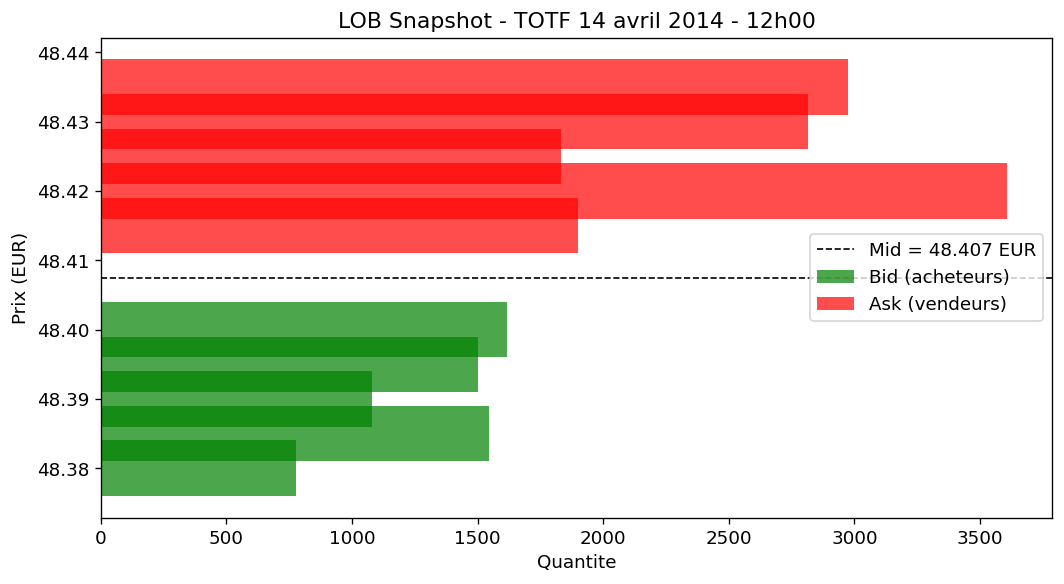

In [12]:
# ============================================================
# Snapshot statique : etat du LOB a un instant donne
# ============================================================
def plot_lob_snapshot(row, ax=None, title=None):
    """Affiche un snapshot du carnet d'ordres (5 niveaux)."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    bid_prices = [row[f'bid_{i}'] for i in range(1, 6)]
    bid_qtys   = [row[f'bidQ_{i}'] for i in range(1, 6)]
    ask_prices = [row[f'ask_{i}'] for i in range(1, 6)]
    ask_qtys   = [row[f'askQ_{i}'] for i in range(1, 6)]

    ax.barh(bid_prices, bid_qtys,  height=0.008, color='green', alpha=0.7, label='Bid (acheteurs)')
    ax.barh(ask_prices, ask_qtys,  height=0.008, color='red',   alpha=0.7, label='Ask (vendeurs)')

    mid    = (bid_prices[0] + ask_prices[0]) / 2
    spread = ask_prices[0] - bid_prices[0]
    ax.axhline(mid, color='black', linestyle='--', linewidth=1, label=f'Mid = {mid:.3f} EUR')
    ax.set_xlabel('Quantite')
    ax.set_ylabel('Prix (EUR)')
    ax.set_title(title or f'LOB Snapshot  |  Spread = {spread:.4f} EUR')
    ax.legend(loc='right')
    return ax

day1 = df_book[df_book['date'] == '2014-04-14'].copy()
day1['hour'] = day1['datetime'].dt.hour + day1['datetime'].dt.minute / 60
mid_day = day1[(day1['hour'] >= 12) & (day1['hour'] < 12.1)].iloc[0]

fig, ax = plt.subplots(figsize=(9, 5))
plot_lob_snapshot(mid_day, ax=ax, title='LOB Snapshot - TOTF 14 avril 2014 - 12h00')
plt.tight_layout()
plt.savefig('lob_snapshot.png')
plt.show()

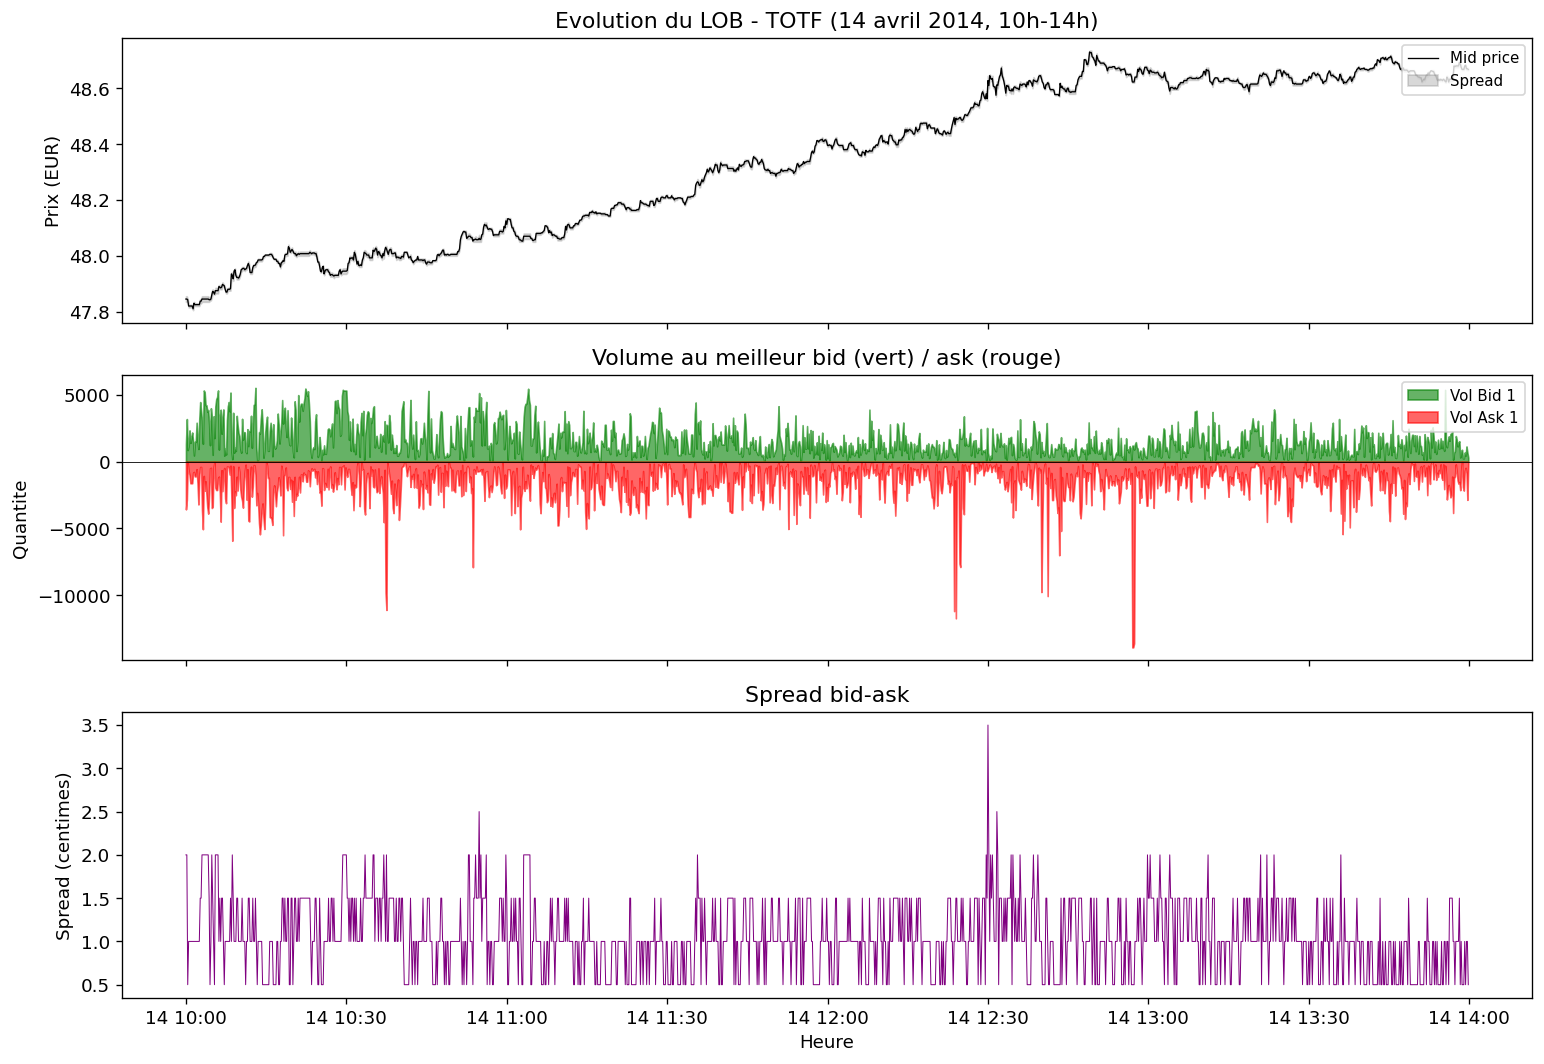

In [13]:
# ============================================================
# Evolution du LOB dans le temps
# ============================================================
day1_mkt = day1[(day1['hour'] >= 10) & (day1['hour'] < 14)].copy()
day1_mkt = day1_mkt.set_index('datetime').resample('10s').last().dropna(subset=['bid_1'])

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

ax = axes[0]
ax.plot(day1_mkt.index, day1_mkt['mid'], color='black', linewidth=0.8, label='Mid price')
ax.fill_between(day1_mkt.index, day1_mkt['bid_1'], day1_mkt['ask_1'],
                alpha=0.3, color='gray', label='Spread')
ax.set_ylabel('Prix (EUR)')
ax.set_title('Evolution du LOB - TOTF (14 avril 2014, 10h-14h)')
ax.legend(loc='upper right', fontsize=9)

ax2 = axes[1]
ax2.fill_between(day1_mkt.index,  day1_mkt['bidQ_1'], alpha=0.6, color='green', label='Vol Bid 1')
ax2.fill_between(day1_mkt.index, -day1_mkt['askQ_1'], alpha=0.6, color='red',   label='Vol Ask 1')
ax2.axhline(0, color='black', linewidth=0.5)
ax2.set_ylabel('Quantite')
ax2.set_title('Volume au meilleur bid (vert) / ask (rouge)')
ax2.legend(loc='upper right', fontsize=9)

ax3 = axes[2]
ax3.plot(day1_mkt.index, day1_mkt['spread'] * 100, color='purple', linewidth=0.6)
ax3.set_ylabel('Spread (centimes)')
ax3.set_title('Spread bid-ask')
ax3.set_xlabel('Heure')

plt.tight_layout()
plt.savefig('lob_evolution.png')
plt.show()

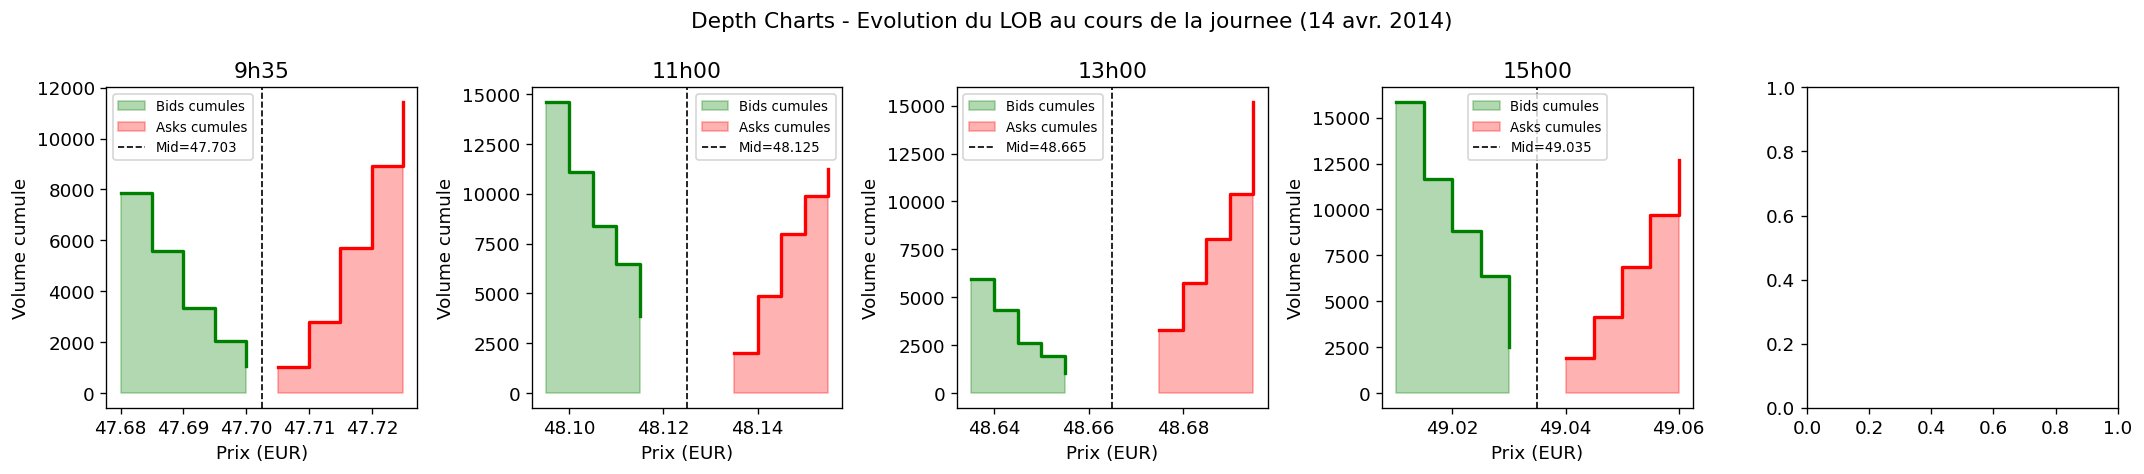

In [14]:
# ============================================================
# Depth Chart : profondeur cumulee du LOB
# ============================================================
def plot_depth_chart(row, ax=None, title=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 5))

    bid_prices = np.array([row[f'bid_{i}'] for i in range(1, 6)])
    bid_qtys   = np.array([row[f'bidQ_{i}'] for i in range(1, 6)])
    ask_prices = np.array([row[f'ask_{i}'] for i in range(1, 6)])
    ask_qtys   = np.array([row[f'askQ_{i}'] for i in range(1, 6)])

    bid_cum = np.cumsum(bid_qtys)
    ask_cum = np.cumsum(ask_qtys)

    ax.step(bid_prices[::-1], bid_cum[::-1], where='post', color='green', linewidth=2)
    ax.fill_between(bid_prices[::-1], bid_cum[::-1], step='post', alpha=0.3, color='green', label='Bids cumules')

    ax.step(ask_prices, ask_cum, where='post', color='red', linewidth=2)
    ax.fill_between(ask_prices, ask_cum, step='post', alpha=0.3, color='red', label='Asks cumules')

    mid = (bid_prices[0] + ask_prices[0]) / 2
    ax.axvline(mid, color='black', linestyle='--', linewidth=1, label=f'Mid={mid:.3f}')
    ax.set_xlabel('Prix (EUR)')
    ax.set_ylabel('Volume cumule')
    ax.set_title(title or '')
    ax.legend(fontsize=8)
    return ax

snapshots_hours = [9.6, 11.0, 13.0, 15.0, 16.8]
fig, axes = plt.subplots(1, len(snapshots_hours), figsize=(18, 4), sharey=False)

for ax, h in zip(axes, snapshots_hours):
    sub = day1[(day1['hour'] >= h) & (day1['hour'] < h + 0.15)]
    if len(sub) == 0:
        continue
    snap = sub.iloc[0]
    plot_depth_chart(snap, ax=ax, title=f'{int(h)}h{int((h%1)*60):02d}')

fig.suptitle('Depth Charts - Evolution du LOB au cours de la journee (14 avr. 2014)', fontsize=13)
plt.tight_layout()
plt.savefig('lob_depth_charts.png')
plt.show()

In [15]:
# ============================================================
# Resume final
# ============================================================
print('=== RESUME DE L ANALYSE ===')
print(f'Actif        : Total SA (TOTF) - Euronext Paris')
print(f'Periode      : {df_book["date"].min()} a {df_book["date"].max()}')
print(f'Trades       : {len(df_trade):,} transactions')
print(f'Book updates : {len(df_book):,} mises a jour')
print()
print('--- Stylised Facts reproduits ---')
print('1. Long Memory       : ACF(signe rendements) > 0 sur >100 lags')
print('2. Bid-Ask Bounce    : ACF(rendements) < 0 au lag 1')
print('3. Market Impact     : impact proportionnel a sqrt(volume)')
print('4. Profil en U       : volumes eleves en ouverture et cloture')
print('5. Heavy Tails       : kurtosis >> 0 (queues epaisses vs gaussienne)')
print('6. Volat. Clustering : ACF(r^2) > 0 sur de nombreux lags')

=== RESUME DE L ANALYSE ===
Actif        : Total SA (TOTF) - Euronext Paris
Periode      : 2014-04-14 a 2014-04-23
Trades       : 29,096 transactions
Book updates : 2,521,765 mises a jour

--- Stylised Facts reproduits ---
1. Long Memory       : ACF(signe rendements) > 0 sur >100 lags
2. Bid-Ask Bounce    : ACF(rendements) < 0 au lag 1
3. Market Impact     : impact proportionnel a sqrt(volume)
4. Profil en U       : volumes eleves en ouverture et cloture
5. Heavy Tails       : kurtosis >> 0 (queues epaisses vs gaussienne)
6. Volat. Clustering : ACF(r^2) > 0 sur de nombreux lags
